# Multicollinearity and PCA — Severe Wasting (MICS Bangladesh)

This notebook complements `models_m.ipynb`. It examines predictor redundancy and PCA separately for (A) all children aged 0–4 and (B) children aged 0–1 completed years (under 2). It does **not** change or replace the prediction models. Run from the repository root and confirm the predictor lists against the final variable-selection cells in `models_m.ipynb` before interpreting results.

**Important:** PCA is unsupervised and does not use the outcome to construct components. One-hot encoding is used for categorical predictors; components are exploratory and are not automatically preferable to original variables.

In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

RANDOM_STATE = 42
pd.set_option('display.max_columns', 120)
sns.set_theme(style='whitegrid')

## 1. Load the analysis data
The loader tries the common project-level dataset names. If your prepared analysis file has another name, set `DATA_PATH` explicitly. The notebook accepts CSV or Stata `.dta` files.

In [12]:
CANDIDATE_PATHS = [
    Path('MICS-child-ISRC.dta'), Path('child_full.csv'),
    Path('data/child_full.csv'), Path('data/MICS-child-ISRC.dta')
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Set DATA_PATH to your prepared MICS file.')
print('Loading:', DATA_PATH)
if DATA_PATH.suffix.lower() == '.dta':
    df = pd.read_stata(DATA_PATH, convert_categoricals=False)
else:
    df = pd.read_csv(DATA_PATH, low_memory=False)
print('Shape:', df.shape)
display(df.head())

# Standardise column lookup while preserving the original dataframe.
column_lookup = {str(c).lower(): c for c in df.columns}
def find_col(name):
    return column_lookup.get(name.lower())

TARGET_COL = find_col('severe_wasting')
if TARGET_COL is None:
    whz_col = find_col('WHZ') or find_col('whz')
    if whz_col is not None:
        df['severe_wasting'] = (pd.to_numeric(df[whz_col], errors='coerce') < -3).astype('float')
        TARGET_COL = 'severe_wasting'
if TARGET_COL is None:
    raise KeyError('Could not find severe_wasting or WHZ. Confirm the outcome column.')
print('Outcome:', TARGET_COL, '\nOutcome counts (including missing):')
display(df[TARGET_COL].value_counts(dropna=False).to_frame('count'))

Loading: MICS-child-ISRC.dta
Shape: (22311, 49)


,hh1,hh2,ln,ub2,chweight,hh7a,wb4,cm11,whz2,strata,child_id,mother_id,hh_id,bd9,diarrhoea_2w,cough_2w,breathing_2w,severe_wasting,mod_wasting,any_wasting,wast_cat,young,has_mother,fg_grain,fg_legume,fg_dairy,fg_flesh,fg_egg,fg_vita,fg_ofv,dds,fvs,anc_cat,fuel_cat,water_cat,toilet_cat,edu_level,mother_married,insured,bf_status,bottle,any_illness,mage_cat,parity_cat,urban,electricity,female,wealth,division
0,1.0,1.0,3.0,1.0,0.418492,BARGUNA,31.0,4.0,-0.64,1.0,1.0,1.0,1.0,3.0,0.0,1.0,1.0,0,0,0,0,1,1,1.0,0.0,0.0,1.0,1.0,0.0,1.0,4.0,5.0,1.0,2,1,1,1.0,1.0,0.0,2.0,0.0,1.0,4.0,4.0,0,1,0,1,1
1,1.0,3.0,5.0,2.0,0.418492,BARGUNA,22.0,2.0,0.20,1.0,2.0,2.0,2.0,NaN,0.0,0.0,0.0,0,0,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,2,1.0,1.0,0.0,NaN,NaN,0.0,2.0,2.0,0,1,0,3,1
2,1.0,6.0,4.0,0.0,0.418492,BARGUNA,24.0,2.0,-1.11,1.0,3.0,3.0,3.0,2.0,0.0,0.0,0.0,0,0,0,0,1,1,1.0,0.0,0.0,0.0,1.0,1.0,0.0,3.0,3.0,2.0,1,1,0,4.0,1.0,0.0,2.0,0.0,0.0,2.0,2.0,0,1,1,5,1
3,1.0,6.0,5.0,3.0,0.418492,BARGUNA,24.0,2.0,-0.46,1.0,4.0,3.0,3.0,NaN,0.0,0.0,0.0,0,0,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,4.0,1.0,0.0,NaN,NaN,0.0,2.0,2.0,0,1,0,5,1
4,1.0,12.0,7.0,0.0,0.418492,BARGUNA,16.0,1.0,-1.76,1.0,5.0,4.0,4.0,4.0,1.0,0.0,0.0,0,0,0,0,1,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,2.0,2,1,1,3.0,1.0,0.0,2.0,0.0,1.0,1.0,1.0,0,1,0,1,1


Outcome: severe_wasting 
Outcome counts (including missing):


,count
severe_wasting,
0,21759
1,552


## 2. Define age-specific predictor sets
These lists use the project’s documented predictors and keep survey-design fields out of the feature matrix. Infant-only feeding and ANC variables are used only for the under-2 subset. **Edit the lists if `models_m.ipynb` uses a different final selected-variable set**; this notebook deliberately reports missing columns rather than silently substituting unrelated variables.

In [13]:
# Core predictors documented in the project. Names are matched case-insensitively.
ALL_CHILDREN_CANDIDATES = [
    'age_years', 'age', 'ub2', 'sex', 'hl4', 'division', 'wealth_index', 'windex5',
    'welevel', 'mother_age', 'wb4', 'cm11', 'mstatus', 'maternal_education',
    'toilet_cat', 'fuel_cat', 'hh6', 'hh7', 'hh7a', 'hc8', 'eu4', 'ws1', 'ws11',
    'bd2', 'bd3', 'bd4', 'bd7a', 'bd7b', 'bd7d', 'bd7e', 'bd8a', 'bd8b',
    'bd8c', 'bd8d', 'bd8e', 'bd8f', 'bd8g', 'bd8h', 'bd8i', 'bd8j', 'bd8k',
    'bd8l', 'bd8m', 'bd8n', 'birth_order', 'number_of_births', 'diarrhoea', 'cough', 'breathing_difficulty'
]
INFANT_EXTRA_CANDIDATES = ['dds', 'fvs', 'fg_grain', 'fg_pulse', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vit_a', 'fg_other_fruits_vegetables', 'bf_status', 'bottle', 'anc_cat', 'bd9']

# Variables that must never be predictors: outcome, identifiers/design variables,
# and variables derived directly from WHZ / wasting outcome.
FORBIDDEN_NAMES = {
    'severe_wasting', 'whz', 'whz2', 'mod_wasting', 'any_wasting', 'wast_cat',
    'hh1', 'hh2', 'ln', 'chweight', 'strata', 'psu', 'cluster', 'id'
}

def resolve_columns(candidates):
    found, missing = [], []
    for name in candidates:
        actual = find_col(name)
        if actual is None: missing.append(name)
        elif str(actual).lower() not in FORBIDDEN_NAMES and actual not in found: found.append(actual)
    return found, missing

all_predictors, missing_all = resolve_columns(ALL_CHILDREN_CANDIDATES)
infant_extra, missing_infant = resolve_columns(INFANT_EXTRA_CANDIDATES)
print('All-children predictors found:', len(all_predictors))
print('Candidate names not found (all children):', missing_all)
print('Infant-specific predictors found:', len(infant_extra))
print('Candidate names not found (infant):', missing_infant)
display(pd.DataFrame({'all_children_predictors': pd.Series(all_predictors), 'infant_extra_predictors': pd.Series(infant_extra)}))

# Resolve age. Prefer the project's completed-age field if present.
AGE_COL = next((find_col(x) for x in ['age_years', 'ub2', 'age'] if find_col(x) is not None), None)
if AGE_COL is None:
    raise KeyError('Age column not found. Set AGE_COL to the completed-age-in-years variable.')
print('Age field used for under-2 filter:', AGE_COL)

# Remove generic age candidates from list if it is not the selected age column, then add chosen field once.
all_predictors = [c for c in all_predictors if c.lower() not in {'age_years','age','ub2'}]
all_predictors = [AGE_COL] + all_predictors
infant_predictors = list(dict.fromkeys(all_predictors + infant_extra))


All-children predictors found: 7
Candidate names not found (all children): ['age_years', 'age', 'sex', 'hl4', 'wealth_index', 'windex5', 'welevel', 'mother_age', 'mstatus', 'maternal_education', 'hh6', 'hh7', 'hc8', 'eu4', 'ws1', 'ws11', 'bd2', 'bd3', 'bd4', 'bd7a', 'bd7b', 'bd7d', 'bd7e', 'bd8a', 'bd8b', 'bd8c', 'bd8d', 'bd8e', 'bd8f', 'bd8g', 'bd8h', 'bd8i', 'bd8j', 'bd8k', 'bd8l', 'bd8m', 'bd8n', 'birth_order', 'number_of_births', 'diarrhoea', 'cough', 'breathing_difficulty']
Infant-specific predictors found: 10
Candidate names not found (infant): ['fg_pulse', 'fg_vit_a', 'fg_other_fruits_vegetables']


,all_children_predictors,infant_extra_predictors
0,ub2,dds
1,division,fvs
2,wb4,fg_grain
3,cm11,fg_dairy
4,toilet_cat,fg_flesh
5,fuel_cat,fg_egg
6,hh7a,bf_status
7,NaN,bottle
8,NaN,anc_cat
9,NaN,bd9


Age field used for under-2 filter: ub2


## 3. Prepare comparable analysis samples
Missing values are imputed within preprocessing pipelines for diagnostic purposes only. The missingness table is retained because missingness may be structural, especially for infant-feeding fields. Do not interpret these diagnostic imputations as a final inferential or predictive preprocessing decision.

In [14]:
def make_sample(data, predictors, infant=False):
    cols = list(dict.fromkeys(predictors))
    work = data.copy()
    if infant:
        age = pd.to_numeric(work[AGE_COL], errors='coerce')
        work = work.loc[age.isin([0, 1])].copy()
    work = work.loc[work[TARGET_COL].notna()].copy()
    usable = [c for c in cols if c in work.columns and c != TARGET_COL and c.lower() not in FORBIDDEN_NAMES]
    X = work[usable].copy()
    y = pd.to_numeric(work[TARGET_COL], errors='coerce')
    valid = y.notna() & y.isin([0, 1])
    X, y = X.loc[valid], y.loc[valid].astype(int)
    # Drop all-empty columns; they cannot be imputed or analysed.
    all_missing = X.columns[X.isna().all()].tolist()
    X = X.drop(columns=all_missing)
    return X, y, work.loc[valid], all_missing

X_all, y_all, sample_all, empty_all = make_sample(df, all_predictors, infant=False)
X_inf, y_inf, sample_inf, empty_inf = make_sample(df, infant_predictors, infant=True)
print(f'All children: n={len(X_all):,}; cases={int(y_all.sum()):,}; predictors={X_all.shape[1]}')
print(f'Under 2:      n={len(X_inf):,}; cases={int(y_inf.sum()):,}; predictors={X_inf.shape[1]}')
print('All-empty columns removed:', empty_all, empty_inf)

def missingness_table(X):
    out = pd.DataFrame({'missing_n': X.isna().sum(), 'missing_pct': 100*X.isna().mean(), 'unique_nonmissing': X.nunique(dropna=True)})
    return out.sort_values('missing_pct', ascending=False)
display(missingness_table(X_all))
display(missingness_table(X_inf))

All children: n=22,311; cases=552; predictors=7
Under 2:      n=8,888; cases=297; predictors=17
All-empty columns removed: [] []


,missing_n,missing_pct,unique_nonmissing
cm11,268,1.201201,10
wb4,259,1.160862,35
ub2,0,0.000000,5
division,0,0.000000,8
toilet_cat,0,0.000000,4
fuel_cat,0,0.000000,5
hh7a,0,0.000000,67


,missing_n,missing_pct,unique_nonmissing
bd9,2360,26.552655,7
anc_cat,90,1.012601,3
fvs,89,1.001350,17
dds,73,0.821332,8
cm11,34,0.382538,10
wb4,32,0.360036,35
fg_dairy,22,0.247525,2
fg_flesh,14,0.157516,2
fg_egg,11,0.123762,2
fg_grain,6,0.067507,2


## 4. Multicollinearity — mixed-type predictor overlap
For categorical predictors, inspect Cramér’s V; for numeric pairs, inspect absolute Pearson correlation. These are pairwise screens, not complete multivariable diagnostics. Perfectly duplicated or deterministically derived features should be separated (for example, `dds` and its constituent food-group indicators).

C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[a].fillna('__MISSING__'), X[b].fillna('__MISSING__'))))
C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[a].fillna('__MISSING__'), X[b].fillna('__MISSING__'))))
C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[

,variable_1,variable_2,cramers_v
8,division,hh7a,0.998676
14,fuel_cat,hh7a,0.385794
13,toilet_cat,hh7a,0.297389
7,division,fuel_cat,0.244532
12,toilet_cat,fuel_cat,0.168229
6,division,toilet_cat,0.150075
11,cm11,hh7a,0.075343
1,ub2,cm11,0.074950
5,division,cm11,0.059856
9,cm11,toilet_cat,0.050938


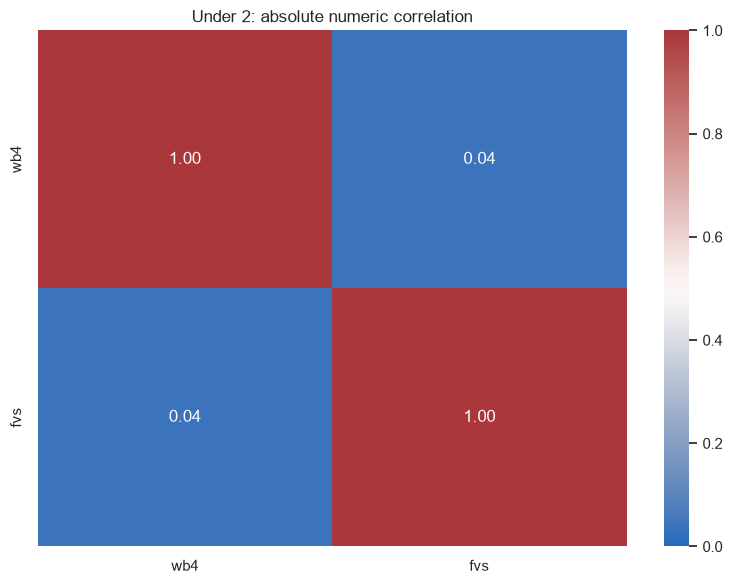

abs_correlation
wb4 fvs         0.036919
    wb4              NaN
fvs wb4              NaN
    fvs              NaN

C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[a].fillna('__MISSING__'), X[b].fillna('__MISSING__'))))
C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[a].fillna('__MISSING__'), X[b].fillna('__MISSING__'))))
C:\Users\User\AppData\Local\Temp\ipykernel_21532\783109750.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rows.append((a,b,cramers_v(X[

,variable_1,variable_2,cramers_v
17,division,hh7a,0.996672
69,dds,fg_grain,0.631214
5,ub2,dds,0.574495
83,fg_grain,bd9,0.574393
13,ub2,bd9,0.555678
71,dds,fg_flesh,0.554181
6,ub2,fg_grain,0.529986
72,dds,fg_egg,0.511528
70,dds,fg_dairy,0.494326
8,ub2,fg_flesh,0.421953


In [15]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    if tab.empty or min(tab.shape) < 2: return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    if n == 0: return np.nan
    phi2 = chi2 / n
    r, k = tab.shape
    # Bias-corrected Cramer's V
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1)) if n > 1 else 0
    rc = r - ((r-1)**2)/(n-1) if n > 1 else r
    kc = k - ((k-1)**2)/(n-1) if n > 1 else k
    denom = min(kc-1, rc-1)
    return np.sqrt(phi2corr/denom) if denom > 0 else np.nan

def variable_types(X):
    numeric = [c for c in X if pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique(dropna=True) > 10]
    categorical = [c for c in X if c not in numeric]
    return numeric, categorical

def pairwise_overlap(X, label):
    numeric, categorical = variable_types(X)
    if len(numeric) >= 2:
        corr = X[numeric].apply(pd.to_numeric, errors='coerce').corr().abs()
        plt.figure(figsize=(max(8, len(numeric)*0.65), max(6, len(numeric)*0.55)))
        sns.heatmap(corr, cmap='vlag', vmin=0, vmax=1, annot=len(numeric)<=12, fmt='.2f')
        plt.title(f'{label}: absolute numeric correlation'); plt.tight_layout(); plt.show()
        pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
        display(pairs.head(20).rename('abs_correlation').to_frame())
    rows = []
    for i, a in enumerate(categorical):
        for b in categorical[i+1:]:
            rows.append((a,b,cramers_v(X[a].fillna('__MISSING__'), X[b].fillna('__MISSING__'))))
    if rows:
        display(pd.DataFrame(rows, columns=['variable_1','variable_2','cramers_v']).sort_values('cramers_v', ascending=False).head(30))

pairwise_overlap(X_all, 'All children')
pairwise_overlap(X_inf, 'Under 2')

## 5. Variance Inflation Factors (VIF)
VIF is calculated on the one-hot encoded design matrix after median/mode imputation, with one reference category dropped. This avoids the dummy-variable trap. VIFs for individual dummy columns should be interpreted cautiously; inspect groups of related variables as well. The common 5/10 thresholds are heuristics, not automatic deletion rules.

In [16]:
def make_design_matrix(X):
    numeric, categorical = variable_types(X)
    transformers = []
    if numeric:
        transformers.append(('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric))
    if categorical:
        transformers.append(('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), categorical))
    prep = ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)
    arr = prep.fit_transform(X)
    names = prep.get_feature_names_out()
    mat = pd.DataFrame(arr, columns=names, index=X.index)
    # Remove constant columns and any remaining duplicate columns.
    mat = mat.loc[:, mat.nunique(dropna=False) > 1]
    mat = mat.loc[:, ~mat.T.duplicated()]
    return mat

def calculate_vif(X, label):
    design = make_design_matrix(X)
    if design.shape[1] < 2:
        print(f'{label}: not enough encoded columns for VIF'); return pd.DataFrame()
    # VIF can be unstable when the encoded matrix is rank-deficient; report infinities rather than hiding them.
    values = []
    arr = add_constant(design, has_constant='add')
    for i, col in enumerate(arr.columns):
        if col == 'const': continue
        try: vif = variance_inflation_factor(arr.to_numpy(dtype=float), i)
        except Exception: vif = np.inf
        values.append((col, vif))
    result = pd.DataFrame(values, columns=['encoded_feature','VIF']).sort_values('VIF', ascending=False)
    print(label, '| encoded columns:', design.shape[1])
    display(result.head(40))
    print('Features with VIF > 5:', int((result.VIF > 5).sum()), '| VIF > 10:', int((result.VIF > 10).sum()))
    return result

vif_all = calculate_vif(X_all, 'All children')
vif_inf = calculate_vif(X_inf, 'Under 2')

C:\Users\User\AppData\Local\Temp\ipykernel_21532\3962894850.py:26: UserWarning: The design matrix is poorly conditioned (condition number=1.31e+15). VIF calculations may be numerically unstable.
  try: vif = variance_inflation_factor(arr.to_numpy(dtype=float), i)
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters ar

All children | encoded columns: 94


,encoded_feature,VIF
80,hh7a_PATUAKHALI,1.437222e+07
56,hh7a_KHAGRACHHARI,1.208868e+07
65,hh7a_MANIKGANJ,1.115745e+07
68,hh7a_MUNSHIGANJ,1.080435e+07
53,hh7a_JHALOKATI,1.045753e+07
51,hh7a_JAMALPUR,1.026628e+07
49,hh7a_GOPALGANJ,9.181290e+06
81,hh7a_PIROJPUR,9.123751e+06
48,hh7a_GAZIPUR,8.873205e+06
45,hh7a_FARIDPUR,8.285063e+06


Features with VIF > 5: 70 | VIF > 10: 69


C:\Users\User\AppData\Local\Temp\ipykernel_21532\3962894850.py:26: UserWarning: The design matrix is poorly conditioned (condition number=6.27e+15). VIF calculations may be numerically unstable.
  try: vif = variance_inflation_factor(arr.to_numpy(dtype=float), i)
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters ar

Under 2 | encoded columns: 114


c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,encoded_feature,VIF
54,hh7a_KHAGRACHHARI,1.164364e+08
47,hh7a_GOPALGANJ,3.128467e+07
90,hh7a_TANGAIL,1.844254e+07
67,hh7a_MYMENSINGH,1.819283e+07
66,hh7a_MUNSHIGANJ,1.626396e+07
45,hh7a_GAIBANDHA,1.583118e+07
73,hh7a_NETRAKONA,1.314109e+07
29,hh7a_BHOLA,1.201019e+07
40,hh7a_DHAKA NORTH CITY CORPORATION,1.087250e+07
70,hh7a_NARAYANGANJ,1.063564e+07


Features with VIF > 5: 76 | VIF > 10: 72


## 6. PCA on the predictor matrix
PCA requires numeric input, so categorical predictors are one-hot encoded and continuous predictors are standardized. Missing values are imputed within the pipeline. Components reflect predictor variance, **not** association with severe wasting. Survey weights are not used in this ordinary PCA, so results are descriptive rather than design-weighted population estimates.

,component,explained_variance_ratio,cumulative_variance
0,1,0.221987,0.221987
1,2,0.078648,0.300635
2,3,0.067500,0.368135
3,4,0.056382,0.424518
4,5,0.043126,0.467643
5,6,0.041619,0.509262
6,7,0.040278,0.549540
7,8,0.038434,0.587974
8,9,0.035132,0.623107
9,10,0.032973,0.656080


All children (0–4): 18 components explain at least 80% of encoded predictor variance.


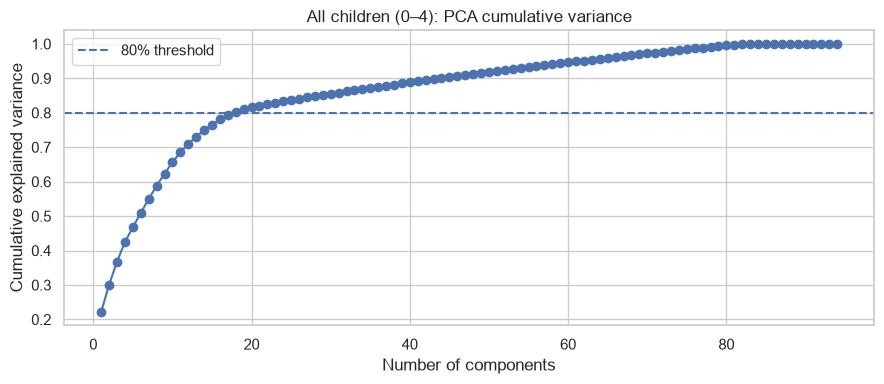

Top absolute loadings for PC1:


,PC1
wb4,0.943127
cm11_1.0,-0.265359
cm11_3.0,0.154825
cm11_4.0,0.077699
ub2_4.0,0.068088
ub2_1.0,-0.043129
ub2_3.0,0.034024
cm11_5.0,0.029908
fuel_cat_2,-0.016627
cm11_2.0,-0.015697


Top absolute loadings for PC2:


,PC2
fuel_cat_2,0.651160
fuel_cat_1,-0.647823
division_2,-0.290776
toilet_cat_1,0.144386
division_6,0.126803
division_7,0.116774
division_3,0.047917
hh7a_BANDARBAN,-0.038928
division_5,0.037700
division_8,-0.035366


Top absolute loadings for PC3:


...

,PC4
toilet_cat_1,0.818800
division_3,-0.416484
fuel_cat_1,0.237079
toilet_cat_2,-0.191647
division_7,0.104407
fuel_cat_2,0.096961
division_2,0.096707
division_5,0.072173
cm11_2.0,-0.053556
hh7a_NARAYANGANJ,-0.044345


Top absolute loadings for PC5:


,PC5
division_2,0.635159
division_3,-0.504755
toilet_cat_1,-0.290124
ub2_2.0,-0.214119
fuel_cat_2,0.212976
fuel_cat_1,-0.185881
toilet_cat_2,0.145634
ub2_1.0,0.144571
division_4,-0.084554
ub2_4.0,0.083090


,component,explained_variance_ratio,cumulative_variance
0,1,0.181484,0.181484
1,2,0.130460,0.311944
2,3,0.056769,0.368713
3,4,0.044086,0.412798
4,5,0.038083,0.450882
5,6,0.036912,0.487794
6,7,0.030178,0.517971
7,8,0.028648,0.546620
8,9,0.024412,0.571032
9,10,0.020929,0.591960


Under 2 (ages 0–1): 24 components explain at least 80% of encoded predictor variance.


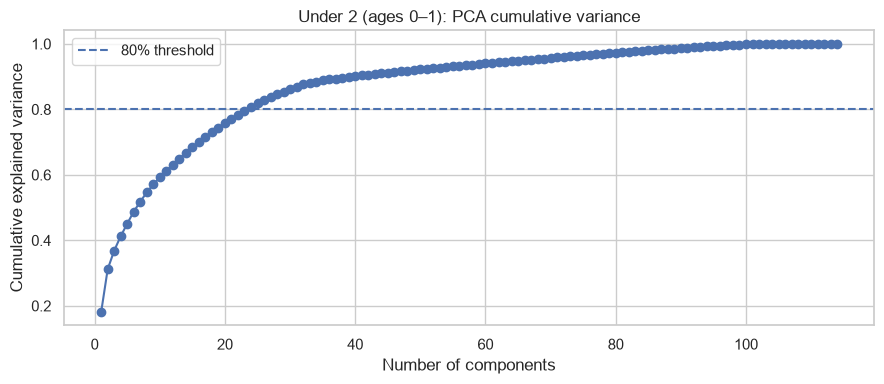

Top absolute loadings for PC1:


,PC1
fvs,0.778897
fg_grain_1.0,0.296347
fg_flesh_1.0,0.255569
ub2_1.0,0.251259
bd9_3.0,-0.235533
fg_egg_1.0,0.222442
dds_4.0,0.109723
fg_dairy_1.0,0.105794
dds_5.0,0.097857
wb4,0.083676


Top absolute loadings for PC2:


,PC2
wb4,0.928374
cm11_1.0,-0.309314
cm11_3.0,0.158248
cm11_4.0,0.073973
fvs,-0.060951
cm11_2.0,0.034338
fg_egg_1.0,-0.030262
fuel_cat_2,-0.027303
cm11_5.0,0.027135
bd9_3.0,0.024712


Top absolute loadings for PC3:


,PC3
anc_cat_2.0,0.633799
anc_cat_1.0,-0.629055
fuel_cat_2,-0.243406
toilet_cat_1,-0.221166
bottle_1.0,0.123989
fg_dairy_1.0,0.114144
fuel_cat_1,0.105537
ub2_1.0,-0.101801
division_3,0.086611
fg_grain_1.0,-0.073031


Top absolute loadings for PC4:


,PC4
fuel_cat_1,0.654757
fuel_cat_2,-0.588593
division_2,0.290674
anc_cat_1.0,0.161448
anc_cat_2.0,-0.154649
fg_dairy_1.0,-0.133970
division_6,-0.125014
division_3,-0.101391
division_7,-0.093773
bottle_1.0,-0.077440


Top absolute loadings for PC5:


,PC5
cm11_2.0,0.735533
cm11_1.0,-0.453175
fg_dairy_1.0,-0.229452
bottle_1.0,-0.209974
cm11_3.0,-0.204147
anc_cat_1.0,-0.142806
wb4,-0.125315
anc_cat_2.0,0.120693
division_3,-0.102850
toilet_cat_1,0.087524


In [17]:
def run_pca(X, label, variance_target=0.80):
    design = make_design_matrix(X)
    if design.shape[1] < 2:
        print(f'{label}: not enough encoded columns for PCA'); return None
    pca = PCA(random_state=RANDOM_STATE)
    scores = pca.fit_transform(design)
    evr = pca.explained_variance_ratio_
    cumulative = np.cumsum(evr)
    n80 = int(np.searchsorted(cumulative, variance_target) + 1)
    summary = pd.DataFrame({'component': np.arange(1, len(evr)+1), 'explained_variance_ratio': evr, 'cumulative_variance': cumulative})
    display(summary.head(20))
    print(f'{label}: {n80} components explain at least {variance_target:.0%} of encoded predictor variance.')
    fig, ax = plt.subplots(figsize=(9,4))
    ax.plot(summary.component, summary.cumulative_variance, marker='o')
    ax.axhline(variance_target, linestyle='--', label=f'{variance_target:.0%} threshold')
    ax.set(xlabel='Number of components', ylabel='Cumulative explained variance', title=f'{label}: PCA cumulative variance')
    ax.legend(); plt.tight_layout(); plt.show()
    loadings = pd.DataFrame(pca.components_.T, index=design.columns, columns=[f'PC{i+1}' for i in range(len(evr))])
    for pc in range(min(5, len(evr))):
        top = loadings.iloc[:, pc].abs().sort_values(ascending=False).head(15).index
        print(f'Top absolute loadings for PC{pc+1}:')
        display(loadings.loc[top, [f'PC{pc+1}']].sort_values(f'PC{pc+1}', key=np.abs, ascending=False))
    return {'pca':pca, 'scores':scores, 'summary':summary, 'loadings':loadings, 'design_columns':design.columns.tolist(), 'n_components_target':n80}

pca_all = run_pca(X_all, 'All children (0–4)')
pca_inf = run_pca(X_inf, 'Under 2 (ages 0–1)')

## 7. Compare PCA structure across age groups
The two groups have different predictor sets by design, so component loadings are not directly comparable when infant-only predictors are present. Use this section to inspect the number of components needed and the strongest loadings within each analysis, not to claim identical components.

In [18]:
comparison = []
for name, result in [('all_children_0_4', pca_all), ('under2_0_1', pca_inf)]:
    if result is not None:
        comparison.append({'analysis': name, 'encoded_features': len(result['design_columns']), 'components_for_80pct_variance': result['n_components_target'], 'variance_first_component': result['summary'].iloc[0]['explained_variance_ratio'], 'variance_first_5_components': result['summary'].head(5)['explained_variance_ratio'].sum()})
display(pd.DataFrame(comparison))

,analysis,encoded_features,components_for_80pct_variance,variance_first_component,variance_first_5_components
0,all_children_0_4,94,18,0.221987,0.467643
1,under2_0_1,114,24,0.181484,0.450882


## 8. Interpretation checklist and cautions
- High VIF / high pairwise overlap suggests redundant predictors; it does not prove a variable is scientifically unnecessary.
- Consider removing or separating deterministic constructions (e.g., dietary diversity score `dds` versus its component food-group indicators). Do not include both in the same model unless there is a clear reason.
- PCA is primarily a dimension-reduction diagnostic. For epidemiologic interpretation, retaining original predictors is often preferable because components can be difficult to explain.
- PCA maximizes predictor variance, not outcome prediction or causal relevance. Any supervised selection must happen inside training folds to avoid leakage.
- This notebook does not calculate survey-design-adjusted VIF/PCA, inferential standard errors, or outcome-informed component selection.
- Before finalizing, reconcile the candidate lists above with the exact variable-selection process in `models_m.ipynb` and document any differences.

In [19]:
# Optional: export diagnostic tables to a local outputs directory.
# Uncomment after reviewing the results.
# Path('outputs').mkdir(exist_ok=True)
# vif_all.to_csv('outputs/vif_all_children.csv', index=False)
# vif_inf.to_csv('outputs/vif_under2.csv', index=False)
# if pca_all is not None: pca_all['summary'].to_csv('outputs/pca_variance_all_children.csv', index=False)
# if pca_inf is not None: pca_inf['summary'].to_csv('outputs/pca_variance_under2.csv', index=False)

## 9. PCA-based prediction: tuned-model comparison

This section evaluates the original notebook's tuned model families on **PCA component scores**. It reads the best configurations recorded in `outputs/tuning_results.csv` by `models_m.ipynb` (run that notebook first, or place its exported tuning-results file in `outputs/`). Configurations are selected separately by cohort and family using the highest mean inner-CV weighted AUC among the saved configurations. PCA and preprocessing are fitted inside each training fold to avoid leaking held-out information.

Metrics shown are weighted ROC-AUC, weighted average precision (PR-AUC), and weighted Brier score. The folds are grouped by PSU/cluster when a suitable design identifier is available. This is a PCA-feature experiment, not a replacement for the original notebook's full nested-CV evaluation; compare the results as a diagnostic and don't treat small differences as definitive.

In [20]:
import json
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

TUNING_RESULTS_PATH = Path("outputs/tuning_results.csv")
if not TUNING_RESULTS_PATH.exists():
    raise FileNotFoundError(
        "Missing outputs/tuning_results.csv. Run models_m.ipynb first and keep its generated outputs/ folder, "
        "or set TUNING_RESULTS_PATH to the exported tuning_results.csv."
    )
tuning_results = pd.read_csv(TUNING_RESULTS_PATH)
required_tuning_cols = {"cohort", "fs", "family", "params", "inner_auc_w_mean"}
missing_tuning_cols = required_tuning_cols - set(tuning_results.columns)
if missing_tuning_cols:
    raise ValueError(f"Unexpected tuning-results schema; missing columns: {sorted(missing_tuning_cols)}")

def find_optional_column(names):
    return next((find_col(n) for n in names if find_col(n) is not None), None)

WEIGHT_COL = find_optional_column(["chweight", "weight", "survey_weight"])
GROUP_COL = find_optional_column(["psu", "hh1", "cluster", "hh2"])
print("Survey weight column:", WEIGHT_COL, "| fold-group column:", GROUP_COL)

def get_best_params(cohort, family):
    rows = tuning_results.loc[
        (tuning_results["cohort"].astype(str) == cohort)
        & (tuning_results["fs"].astype(str) == "FS1")
        & (tuning_results["family"].astype(str).str.upper().isin([family.upper(), {"EN":"EN","RF":"RF","XGB":"XGB","LGBM":"LGBM","CB":"CB"}.get(family.upper(), family.upper())]))
    ].copy()
    if rows.empty:
        return None
    # Prefer configurations explicitly marked selected if the exported file contains that field;
    # otherwise use the best observed mean inner weighted AUC.
    if "selected" in rows.columns and rows["selected"].astype(bool).any():
        rows = rows.loc[rows["selected"].astype(bool)]
    rows["inner_auc_w_mean"] = pd.to_numeric(rows["inner_auc_w_mean"], errors="coerce")
    rows = rows.dropna(subset=["inner_auc_w_mean"]).sort_values("inner_auc_w_mean", ascending=False)
    if rows.empty:
        return None
    params = json.loads(rows.iloc[0]["params"])
    params.pop("scheme", None)
    return params

def estimator_from_best(family, params, seed):
    p = dict(params)
    if family == "EN":
        return LogisticRegression(penalty="elasticnet", solver="saga", C=float(p.get("C", 0.05)),
                                  l1_ratio=float(p.get("l1_ratio", 0.5)), max_iter=3000, tol=1e-3,
                                  random_state=seed)
    if family == "RF":
        return RandomForestClassifier(n_estimators=int(p.get("n_estimators", 80)),
            max_depth=p.get("max_depth", 4), min_samples_leaf=int(p.get("min_samples_leaf", 80)),
            max_features=p.get("max_features", "sqrt"), max_samples=p.get("max_samples", 0.5),
            n_jobs=-1, random_state=seed)
    if family == "XGB":
        from xgboost import XGBClassifier
        allowed = {k:p[k] for k in ["n_estimators","learning_rate","max_depth","min_child_weight","subsample","colsample_bytree","reg_lambda"] if k in p}
        return XGBClassifier(**allowed, tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=seed, verbosity=0)
    if family == "LGBM":
        from lightgbm import LGBMClassifier
        allowed = {k:p[k] for k in ["n_estimators","learning_rate","num_leaves","min_child_samples","subsample","colsample_bytree","reg_lambda"] if k in p}
        return LGBMClassifier(**allowed, subsample_freq=1, n_jobs=-1, random_state=seed, verbosity=-1)
    if family == "CB":
        from catboost import CatBoostClassifier
        allowed = {k:p[k] for k in ["iterations","depth","learning_rate","l2_leaf_reg","random_strength"] if k in p}
        return CatBoostClassifier(**allowed, verbose=False, random_seed=seed, thread_count=-1)
    raise ValueError(f"Unsupported model family: {family}")

def pca_preprocessor(X):
    numeric, categorical = variable_types(X)
    transformers = []
    if numeric:
        transformers.append(("num", Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler())
        ]), numeric))
    if categorical:
        transformers.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
        ]), categorical))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

def evaluate_pca_models(X, y, sample_rows, cohort, pca_variance=0.80, n_splits=5, seed=42):
    y = np.asarray(y, dtype=int)
    X = X.reset_index(drop=True).copy()
    rows = sample_rows.reset_index(drop=True).copy()
    if WEIGHT_COL and WEIGHT_COL in rows:
        weights = pd.to_numeric(rows[WEIGHT_COL], errors="coerce").fillna(0).to_numpy(float)
        weights = np.where(weights > 0, weights, 0)
    else:
        weights = np.ones(len(y), dtype=float)
    groups = rows[GROUP_COL].astype(str).fillna("missing_group").to_numpy() if GROUP_COL and GROUP_COL in rows else None
    if groups is not None and len(np.unique(groups)) >= n_splits:
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        split_iter = splitter.split(X, y, groups)
        split_note = f"grouped by {GROUP_COL}"
    else:
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        split_iter = splitter.split(X, y)
        split_note = "stratified (no usable PSU grouping column found)"
    available = []
    for family in ["EN", "RF", "XGB", "LGBM", "CB"]:
        try:
            params = get_best_params(cohort, family)
            if params is not None:
                estimator_from_best(family, params, seed)
                available.append((family, params))
        except ImportError as e:
            print(f"{cohort}: skipping {family}; optional dependency unavailable: {e}")
    if not available:
        raise ValueError(f"No selected FS1 configurations found for cohort {cohort}. Check tuning_results.csv.")
    fold_rows, shap_models = [], []
    for fold, (train_idx, test_idx) in enumerate(split_iter, start=1):
        Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
        ytr, yte = y[train_idx], y[test_idx]
        wtr, wte = weights[train_idx], weights[test_idx]
        prep = pca_preprocessor(Xtr)
        Ztr_full = prep.fit_transform(Xtr)
        Zte_full = prep.transform(Xte)
        pca = PCA(n_components=pca_variance, svd_solver="full", random_state=seed)
        Ztr, Zte = pca.fit_transform(Ztr_full), pca.transform(Zte_full)
        for family, params in available:
            model = estimator_from_best(family, params, seed + fold)
            fit_kwargs = {}
            if family in ("EN", "RF", "XGB", "LGBM", "CB"):
                fit_kwargs["sample_weight"] = wtr / np.mean(wtr[wtr > 0]) if np.any(wtr > 0) else wtr
            model.fit(Ztr, ytr, **fit_kwargs)
            prob = model.predict_proba(Zte)[:, 1]
            fold_rows.append({
                "cohort": cohort, "fold": fold, "model": family,
                "n_train": len(train_idx), "n_test": len(test_idx),
                "pca_components": Ztr.shape[1],
                "pca_variance_retained": float(pca.explained_variance_ratio_.sum()),
                "roc_auc_weighted": roc_auc_score(yte, prob, sample_weight=wte) if len(np.unique(yte)) == 2 else np.nan,
                "pr_auc_weighted": average_precision_score(yte, prob, sample_weight=wte) if len(np.unique(yte)) == 2 else np.nan,
                "brier_weighted": brier_score_loss(yte, prob, sample_weight=wte),
                "best_params": json.dumps(params, default=str)
            })
            # Save one fold's fitted model and transformed held-out matrix for SHAP, per family.
            if fold == 1:
                shap_models.append({"cohort":cohort, "family":family, "model":model, "Z_test":Zte,
                                    "pca":pca, "preprocessor":prep, "params":params,
                                    "component_names":[f"PC{i+1}" for i in range(Ztr.shape[1])]})
    fold_df = pd.DataFrame(fold_rows)
    summary = (fold_df.groupby(["cohort","model"], as_index=False)
               .agg(roc_auc_mean=("roc_auc_weighted","mean"), roc_auc_sd=("roc_auc_weighted","std"),
                    pr_auc_mean=("pr_auc_weighted","mean"), pr_auc_sd=("pr_auc_weighted","std"),
                    brier_mean=("brier_weighted","mean"), components_mean=("pca_components","mean"),
                    variance_retained_mean=("pca_variance_retained","mean")))
    print(f"{cohort}: {split_note}; PCA is fitted within each fold; variance target={pca_variance:.0%}.")
    return fold_df, summary, shap_models

pca_model_results = {}
for cohort, X, y, sample_rows in [
    ("all", X_all, y_all, sample_all),
    ("0-1", X_inf, y_inf, sample_inf),
]:
    fold_df, summary_df, shap_models = evaluate_pca_models(X, y, sample_rows, cohort)
    pca_model_results[cohort] = {"folds": fold_df, "summary": summary_df, "shap_models": shap_models}
    display(summary_df.sort_values("roc_auc_mean", ascending=False))
    display(fold_df)
    fold_df.to_csv(f"pca_model_fold_metrics_{cohort}.csv", index=False)
    summary_df.to_csv(f"pca_model_summary_{cohort}.csv", index=False)

pca_comparison = pd.concat([v["summary"] for v in pca_model_results.values()], ignore_index=True)
display(pca_comparison.sort_values(["cohort","roc_auc_mean"], ascending=[True,False]))


Survey weight column: chweight | fold-group column: hh1


c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:

all: grouped by hh1; PCA is fitted within each fold; variance target=80%.


,cohort,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,brier_mean,components_mean,variance_retained_mean
1,all,LGBM,0.547692,0.018869,0.035538,0.009628,0.024550,18.0,0.802966
3,all,XGB,0.545515,0.022036,0.032395,0.006686,0.024538,18.0,0.802966
2,all,RF,0.524739,0.028590,0.029912,0.005273,0.024551,18.0,0.802966
0,all,EN,0.518891,0.025905,0.031273,0.004071,0.024543,18.0,0.802966


,cohort,fold,model,n_train,n_test,pca_components,pca_variance_retained,roc_auc_weighted,pr_auc_weighted,brier_weighted,best_params
0,all,1,EN,17849,4462,18,0.803795,0.516164,0.027467,0.024203,"{""l1_ratio"": 0.5, ""C"": 0.03}"
1,all,1,RF,17849,4462,18,0.803795,0.565805,0.034297,0.024171,"{""n_estimators"": 80, ""max_depth"": 4, ""min_samp..."
2,all,1,XGB,17849,4462,18,0.803795,0.561175,0.041429,0.024164,"{""subsample"": 0.8, ""reg_lambda"": 1, ""n_estimat..."
3,all,1,LGBM,17849,4462,18,0.803795,0.575195,0.040744,0.024141,"{""n_estimators"": 100, ""learning_rate"": 0.04, ""..."
4,all,2,EN,17849,4462,18,0.803232,0.548640,0.036780,0.024927,"{""l1_ratio"": 0.5, ""C"": 0.03}"
5,all,2,RF,17849,4462,18,0.803232,0.526818,0.026549,0.024941,"{""n_estimators"": 80, ""max_depth"": 4, ""min_samp..."
6,all,2,XGB,17849,4462,18,0.803232,0.519245,0.027924,0.024957,"{""subsample"": 0.8, ""reg_lambda"": 1, ""n_estimat..."
7,all,2,LGBM,17849,4462,18,0.803232,0.529580,0.028709,0.024967,"{""n_estimators"": 100, ""learning_rate"": 0.04, ""..."
8,all,3,EN,17849,4462,18,0.802525,0.493850,0.030757,0.023746,"{""l1_ratio"": 0.5, ""C"": 0.03}"
9,all,3,RF,17849,4462,18,0.802525,0.508558,0.027323,0.023758,"{""n_estimators"": 80, ""max_depth"": 4, ""min_samp..."


c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:

0-1: grouped by hh1; PCA is fitted within each fold; variance target=80%.


,cohort,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,brier_mean,components_mean,variance_retained_mean
0,0-1,EN,0.561353,0.046779,0.047609,0.011890,0.032097,24.0,0.806934
3,0-1,XGB,0.560365,0.045724,0.043290,0.006271,0.032059,24.0,0.806934
1,0-1,LGBM,0.559876,0.045586,0.044699,0.007332,0.032068,24.0,0.806934
2,0-1,RF,0.540043,0.037268,0.038591,0.005464,0.032077,24.0,0.806934


,cohort,fold,model,n_train,n_test,pca_components,pca_variance_retained,roc_auc_weighted,pr_auc_weighted,brier_weighted,best_params
0,0-1,1,EN,7110,1778,24,0.807079,0.540765,0.039247,0.033667,"{""l1_ratio"": 0.8, ""C"": 1.0}"
1,0-1,1,RF,7110,1778,24,0.807079,0.582362,0.046186,0.033445,"{""n_estimators"": 60, ""min_samples_leaf"": 80, ""..."
2,0-1,1,XGB,7110,1778,24,0.807079,0.608661,0.051883,0.033413,"{""subsample"": 0.8, ""reg_lambda"": 1, ""n_estimat..."
3,0-1,1,LGBM,7110,1778,24,0.807079,0.552686,0.046715,0.033507,"{""subsample"": 0.6, ""reg_lambda"": 10, ""num_leav..."
4,0-1,2,EN,7110,1778,24,0.807388,0.556727,0.044562,0.029527,"{""l1_ratio"": 0.8, ""C"": 1.0}"
5,0-1,2,RF,7110,1778,24,0.807388,0.575616,0.040815,0.029460,"{""n_estimators"": 60, ""min_samples_leaf"": 80, ""..."
6,0-1,2,XGB,7110,1778,24,0.807388,0.588597,0.047038,0.029426,"{""subsample"": 0.8, ""reg_lambda"": 1, ""n_estimat..."
7,0-1,2,LGBM,7110,1778,24,0.807388,0.601354,0.052310,0.029404,"{""subsample"": 0.6, ""reg_lambda"": 10, ""num_leav..."
8,0-1,3,EN,7110,1778,24,0.806476,0.498747,0.037126,0.031478,"{""l1_ratio"": 0.8, ""C"": 1.0}"
9,0-1,3,RF,7110,1778,24,0.806476,0.496298,0.032664,0.031271,"{""n_estimators"": 60, ""min_samples_leaf"": 80, ""..."


,cohort,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,brier_mean,components_mean,variance_retained_mean
4,0-1,EN,0.561353,0.046779,0.047609,0.011890,0.032097,24.0,0.806934
7,0-1,XGB,0.560365,0.045724,0.043290,0.006271,0.032059,24.0,0.806934
5,0-1,LGBM,0.559876,0.045586,0.044699,0.007332,0.032068,24.0,0.806934
6,0-1,RF,0.540043,0.037268,0.038591,0.005464,0.032077,24.0,0.806934
1,all,LGBM,0.547692,0.018869,0.035538,0.009628,0.024550,18.0,0.802966
3,all,XGB,0.545515,0.022036,0.032395,0.006686,0.024538,18.0,0.802966
2,all,RF,0.524739,0.028590,0.029912,0.005273,0.024551,18.0,0.802966
0,all,EN,0.518891,0.025905,0.031273,0.004071,0.024543,18.0,0.802966


## 10. SHAP on PCA components

SHAP values here explain each model's predictions in **principal-component space**, not directly in the original child/household variables. PCA components are weighted combinations of encoded predictors, so component-level SHAP must not be described as a direct original-variable effect. The cell below uses TreeExplainer where supported and falls back to a small KernelExplainer sample if needed. It also reports which original variables have the largest absolute loadings in the most important components as a separate, approximate bridge back to the original feature space.

c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 100/100 [00:00<00:00, 209.24it/s]


,component,mean_abs_shap
4,PC5,8.056474e-04
2,PC3,7.308479e-04
6,PC7,5.539128e-04
0,PC1,6.201969e-05
15,PC16,5.792978e-08
11,PC12,4.514585e-08
10,PC11,2.954583e-08
17,PC18,2.470916e-08
8,PC9,2.147022e-08
5,PC6,1.858010e-08


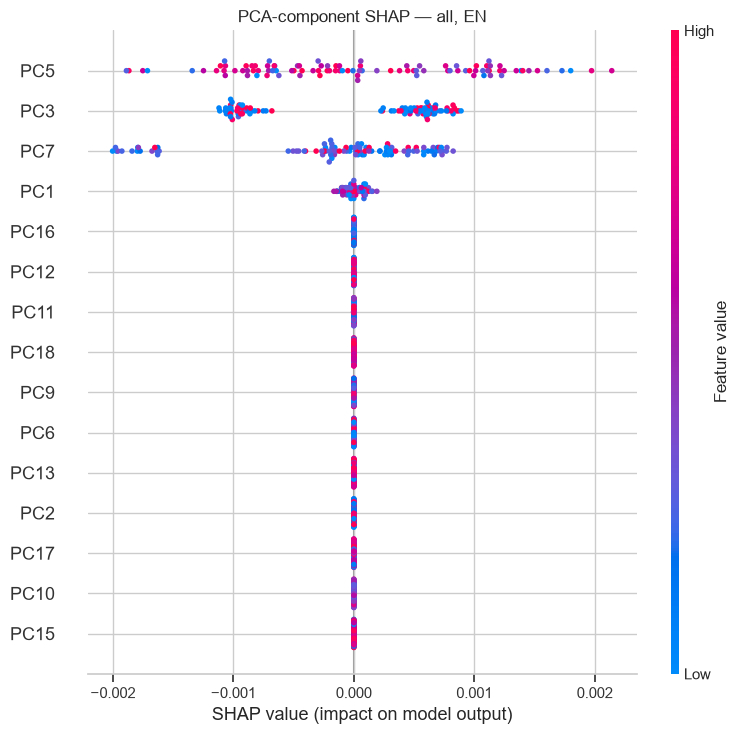

all / EN / PC5: largest absolute original encoded-variable loadings


,loading
division_2,0.651590
division_3,-0.458204
toilet_cat_1,-0.253942
ub2_2.0,-0.246820
fuel_cat_2,0.224678
fuel_cat_1,-0.197270
ub2_1.0,0.179954
toilet_cat_2,0.141557


all / EN / PC3: largest absolute original encoded-variable loadings


,loading
cm11_2.0,0.820754
cm11_1.0,-0.486969
cm11_3.0,-0.251080
wb4,-0.086969
ub2_1.0,-0.076787
ub2_4.0,0.070553
cm11_4.0,-0.057167
toilet_cat_1,0.038945


all / EN / PC7: largest absolute original encoded-variable loadings


...

all / EN / PC1: largest absolute original encoded-variable loadings


,loading
wb4,0.942611
cm11_1.0,-0.266010
cm11_3.0,0.154985
cm11_4.0,0.079368
ub2_4.0,0.067978
ub2_1.0,-0.044210
ub2_3.0,0.035452
cm11_5.0,0.029051


all / EN / PC16: largest absolute original encoded-variable loadings


,loading
toilet_cat_2,0.592244
division_5,0.496295
division_8,-0.440555
cm11_4.0,0.165246
hh7a_JAMALPUR,0.149503
hh7a_NETRAKONA,0.146134
hh7a_SYLHET,-0.139596
hh7a_HABIGANJ,-0.122525


,component,mean_abs_shap
6,PC7,0.001212
4,PC5,0.001103
7,PC8,0.000813
0,PC1,0.000714
1,PC2,0.000697
2,PC3,0.000635
5,PC6,0.000542
15,PC16,0.000531
8,PC9,0.000509
3,PC4,0.000502


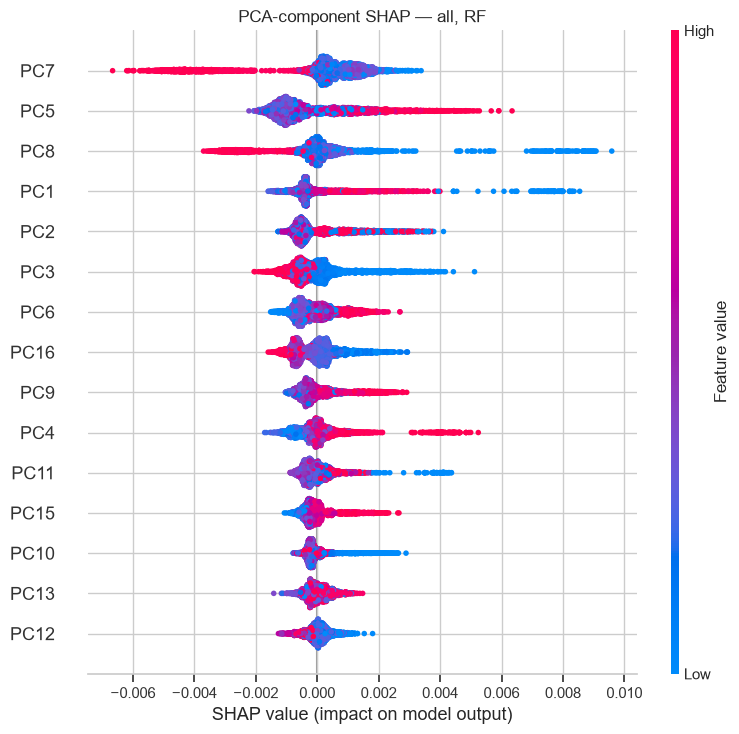

all / RF / PC7: largest absolute original encoded-variable loadings


,loading
ub2_3.0,0.828778
ub2_1.0,-0.465915
ub2_2.0,-0.267506
ub2_4.0,-0.119171
cm11_1.0,0.059209
cm11_2.0,-0.044948
toilet_cat_1,-0.032501
division_7,0.029039


all / RF / PC5: largest absolute original encoded-variable loadings


,loading
division_2,0.651590
division_3,-0.458204
toilet_cat_1,-0.253942
ub2_2.0,-0.246820
fuel_cat_2,0.224678
fuel_cat_1,-0.197270
ub2_1.0,0.179954
toilet_cat_2,0.141557


all / RF / PC8: largest absolute original encoded-variable loadings


...

all / RF / PC1: largest absolute original encoded-variable loadings


,loading
wb4,0.942611
cm11_1.0,-0.266010
cm11_3.0,0.154985
cm11_4.0,0.079368
ub2_4.0,0.067978
ub2_1.0,-0.044210
ub2_3.0,0.035452
cm11_5.0,0.029051


all / RF / PC2: largest absolute original encoded-variable loadings


,loading
fuel_cat_2,0.649306
fuel_cat_1,-0.638697
division_2,-0.301212
toilet_cat_1,0.162970
division_6,0.125998
division_7,0.121814
hh7a_BANDARBAN,-0.045009
division_3,0.044440


,component,mean_abs_shap
6,PC7,0.090422
7,PC8,0.065302
4,PC5,0.064852
0,PC1,0.049137
1,PC2,0.040535
11,PC12,0.025358
12,PC13,0.025283
15,PC16,0.022887
2,PC3,0.021615
8,PC9,0.015689


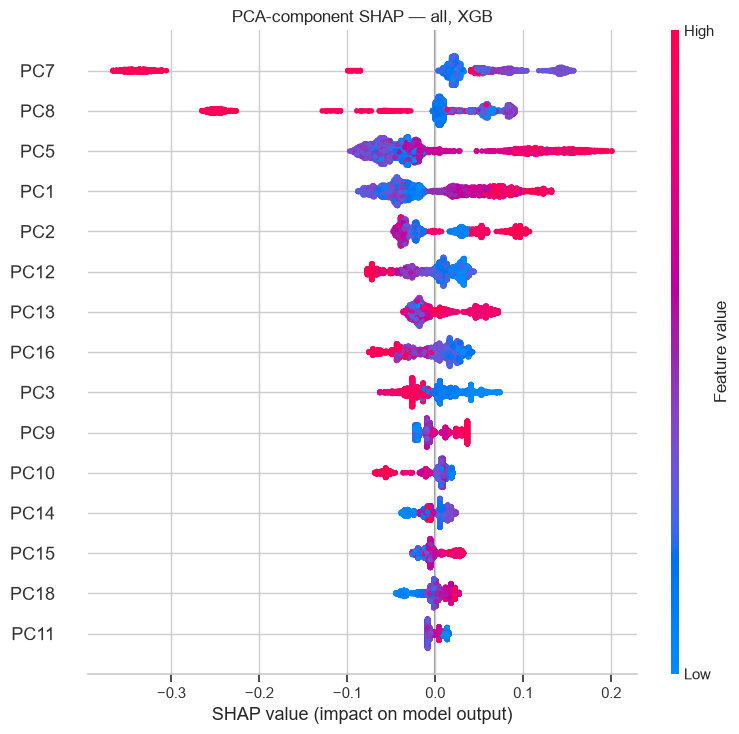

all / XGB / PC7: largest absolute original encoded-variable loadings


,loading
ub2_3.0,0.828778
ub2_1.0,-0.465915
ub2_2.0,-0.267506
ub2_4.0,-0.119171
cm11_1.0,0.059209
cm11_2.0,-0.044948
toilet_cat_1,-0.032501
division_7,0.029039


all / XGB / PC8: largest absolute original encoded-variable loadings


,loading
ub2_4.0,0.831644
ub2_1.0,-0.402532
ub2_2.0,-0.261232
ub2_3.0,-0.207517
cm11_1.0,0.132538
cm11_3.0,-0.080174
cm11_2.0,-0.053537
division_2,-0.050915


all / XGB / PC5: largest absolute original encoded-variable loadings


...

,loading
wb4,0.942611
cm11_1.0,-0.266010
cm11_3.0,0.154985
cm11_4.0,0.079368
ub2_4.0,0.067978
ub2_1.0,-0.044210
ub2_3.0,0.035452
cm11_5.0,0.029051


all / XGB / PC2: largest absolute original encoded-variable loadings


,loading
fuel_cat_2,0.649306
fuel_cat_1,-0.638697
division_2,-0.301212
toilet_cat_1,0.162970
division_6,0.125998
division_7,0.121814
hh7a_BANDARBAN,-0.045009
division_3,0.044440


c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,component,mean_abs_shap
6,PC7,0.111698
7,PC8,0.075129
4,PC5,0.067701
0,PC1,0.055319
1,PC2,0.044559
2,PC3,0.039892
9,PC10,0.026967
11,PC12,0.026123
5,PC6,0.025940
17,PC18,0.024521


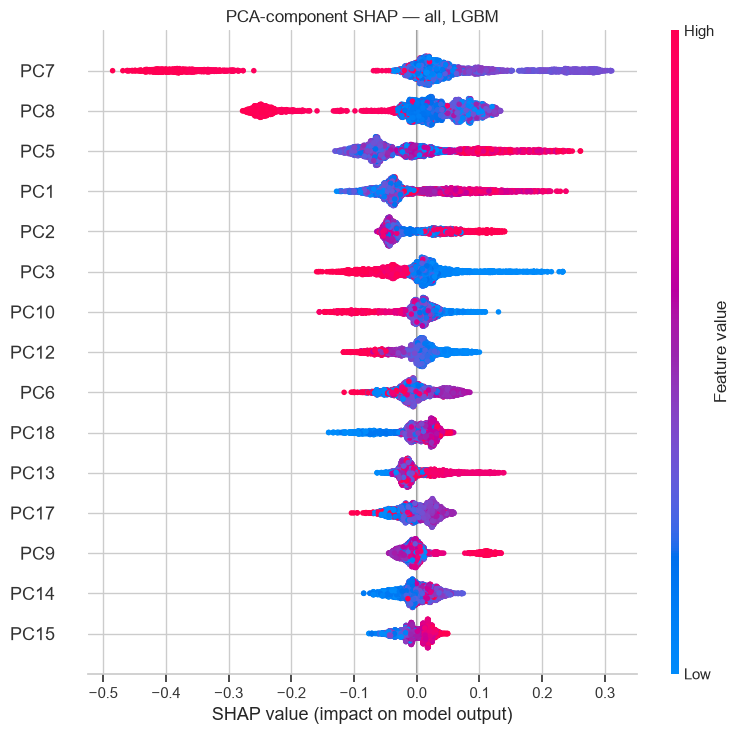

all / LGBM / PC7: largest absolute original encoded-variable loadings


,loading
ub2_3.0,0.828778
ub2_1.0,-0.465915
ub2_2.0,-0.267506
ub2_4.0,-0.119171
cm11_1.0,0.059209
cm11_2.0,-0.044948
toilet_cat_1,-0.032501
division_7,0.029039


all / LGBM / PC8: largest absolute original encoded-variable loadings


,loading
ub2_4.0,0.831644
ub2_1.0,-0.402532
ub2_2.0,-0.261232
ub2_3.0,-0.207517
cm11_1.0,0.132538
cm11_3.0,-0.080174
cm11_2.0,-0.053537
division_2,-0.050915


all / LGBM / PC5: largest absolute original encoded-variable loadings


...

,loading
wb4,0.942611
cm11_1.0,-0.266010
cm11_3.0,0.154985
cm11_4.0,0.079368
ub2_4.0,0.067978
ub2_1.0,-0.044210
ub2_3.0,0.035452
cm11_5.0,0.029051


all / LGBM / PC2: largest absolute original encoded-variable loadings


,loading
fuel_cat_2,0.649306
fuel_cat_1,-0.638697
division_2,-0.301212
toilet_cat_1,0.162970
division_6,0.125998
division_7,0.121814
hh7a_BANDARBAN,-0.045009
division_3,0.044440


100%|██████████| 100/100 [00:00<00:00, 155.63it/s]


,component,mean_abs_shap
0,PC1,0.005814
2,PC3,0.003712
8,PC9,0.003483
12,PC13,0.003242
21,PC22,0.002404
10,PC11,0.002389
4,PC5,0.002260
19,PC20,0.001734
13,PC14,0.001555
1,PC2,0.001498


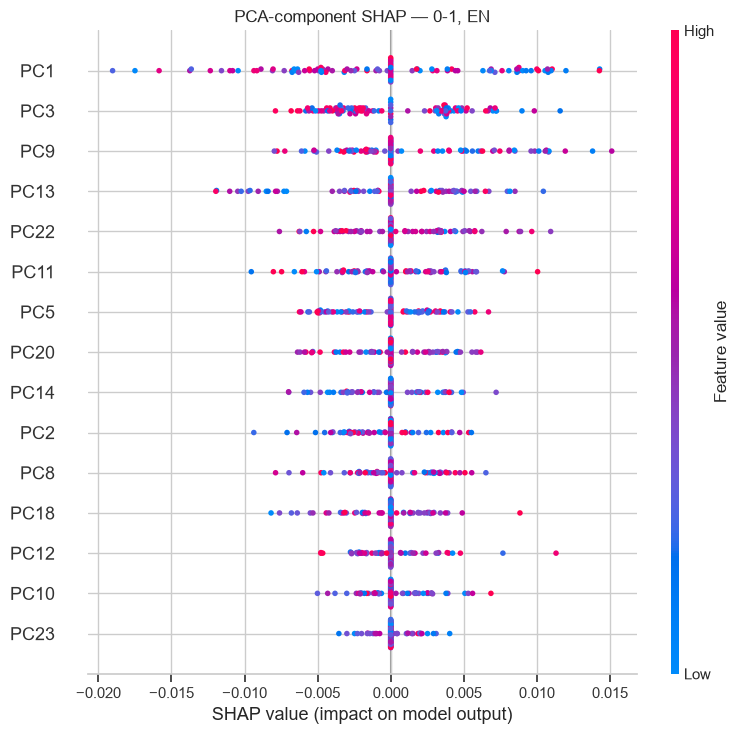

0-1 / EN / PC1: largest absolute original encoded-variable loadings


,loading
fvs,0.779189
fg_grain_1.0,0.298223
fg_flesh_1.0,0.257118
ub2_1.0,0.250119
bd9_3.0,-0.236701
fg_egg_1.0,0.222421
dds_4.0,0.109376
fg_dairy_1.0,0.102656


0-1 / EN / PC3: largest absolute original encoded-variable loadings


,loading
anc_cat_2.0,0.631939
anc_cat_1.0,-0.627393
fuel_cat_2,-0.249888
toilet_cat_1,-0.227252
bottle_1.0,0.121248
fuel_cat_1,0.114016
fg_dairy_1.0,0.109605
ub2_1.0,-0.099866


0-1 / EN / PC9: largest absolute original encoded-variable loadings


...

0-1 / EN / PC13: largest absolute original encoded-variable loadings


,loading
cm11_3.0,0.757091
cm11_1.0,-0.402852
wb4,-0.239588
fg_egg_1.0,-0.229813
cm11_4.0,-0.174363
fg_flesh_1.0,0.148030
division_4,0.124290
cm11_2.0,-0.107502


0-1 / EN / PC22: largest absolute original encoded-variable loadings


,loading
bottle_1.0,0.383009
bd9_2.0,0.330950
bf_status_2.0,0.320343
fg_flesh_1.0,0.297723
bd9_7.0,-0.291660
bf_status_1.0,-0.275566
fuel_cat_2,0.250407
division_7,-0.221420


,component,mean_abs_shap
0,PC1,0.002896
12,PC13,0.001759
7,PC8,0.001713
2,PC3,0.001648
17,PC18,0.001636
19,PC20,0.001633
8,PC9,0.001611
13,PC14,0.001286
1,PC2,0.001002
3,PC4,0.000977


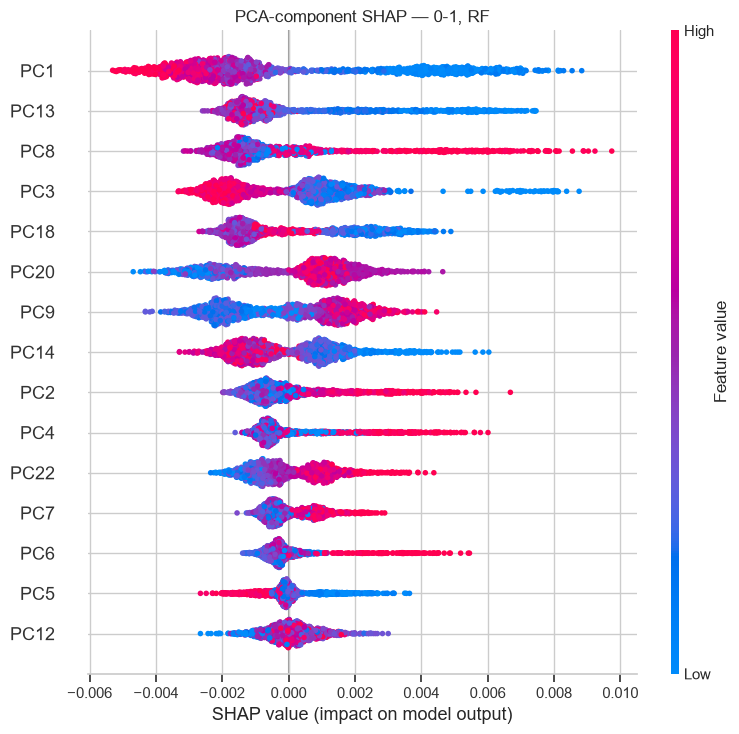

0-1 / RF / PC1: largest absolute original encoded-variable loadings


,loading
fvs,0.779189
fg_grain_1.0,0.298223
fg_flesh_1.0,0.257118
ub2_1.0,0.250119
bd9_3.0,-0.236701
fg_egg_1.0,0.222421
dds_4.0,0.109376
fg_dairy_1.0,0.102656


0-1 / RF / PC13: largest absolute original encoded-variable loadings


,loading
cm11_3.0,0.757091
cm11_1.0,-0.402852
wb4,-0.239588
fg_egg_1.0,-0.229813
cm11_4.0,-0.174363
fg_flesh_1.0,0.148030
division_4,0.124290
cm11_2.0,-0.107502


0-1 / RF / PC8: largest absolute original encoded-variable loadings


...

0-1 / RF / PC3: largest absolute original encoded-variable loadings


,loading
anc_cat_2.0,0.631939
anc_cat_1.0,-0.627393
fuel_cat_2,-0.249888
toilet_cat_1,-0.227252
bottle_1.0,0.121248
fuel_cat_1,0.114016
fg_dairy_1.0,0.109605
ub2_1.0,-0.099866


0-1 / RF / PC18: largest absolute original encoded-variable loadings


,loading
division_6,0.565705
division_4,-0.288917
dds_4.0,0.281087
dds_1.0,-0.241316
bottle_1.0,0.228579
bd9_7.0,0.194225
bf_status_2.0,-0.185992
dds_5.0,-0.185265


,component,mean_abs_shap
0,PC1,0.111023
8,PC9,0.085102
2,PC3,0.072210
17,PC18,0.068535
19,PC20,0.054663
12,PC13,0.050445
7,PC8,0.039532
1,PC2,0.038968
21,PC22,0.028977
3,PC4,0.025791


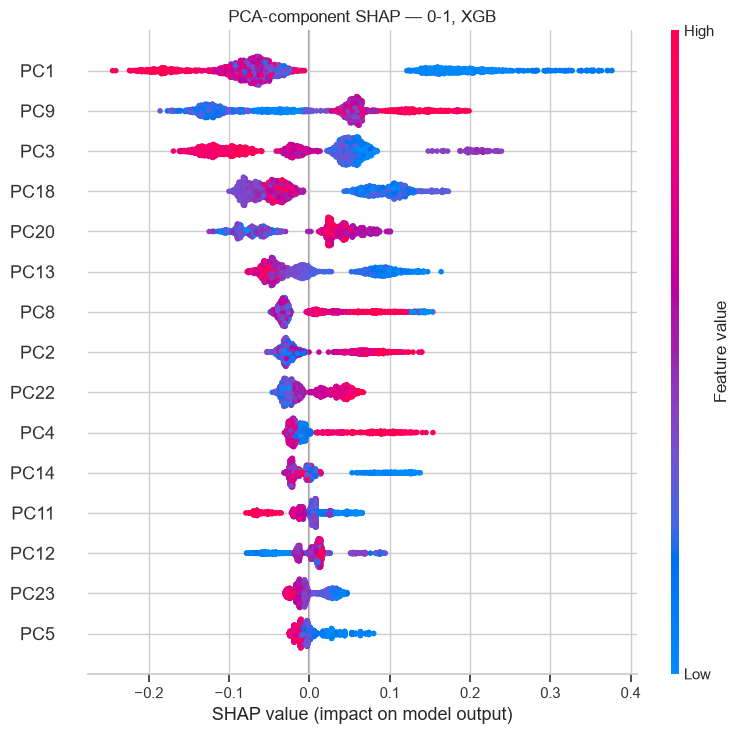

0-1 / XGB / PC1: largest absolute original encoded-variable loadings


,loading
fvs,0.779189
fg_grain_1.0,0.298223
fg_flesh_1.0,0.257118
ub2_1.0,0.250119
bd9_3.0,-0.236701
fg_egg_1.0,0.222421
dds_4.0,0.109376
fg_dairy_1.0,0.102656


0-1 / XGB / PC9: largest absolute original encoded-variable loadings


,loading
division_2,0.683546
division_3,-0.473361
toilet_cat_1,-0.224721
fuel_cat_2,0.207450
fuel_cat_1,-0.179011
division_4,-0.152379
bottle_1.0,0.143868
fg_dairy_1.0,0.134175


0-1 / XGB / PC3: largest absolute original encoded-variable loadings


...

,loading
division_6,0.565705
division_4,-0.288917
dds_4.0,0.281087
dds_1.0,-0.241316
bottle_1.0,0.228579
bd9_7.0,0.194225
bf_status_2.0,-0.185992
dds_5.0,-0.185265


0-1 / XGB / PC20: largest absolute original encoded-variable loadings


,loading
bf_status_2.0,0.388946
bd9_4.0,-0.388733
fg_flesh_1.0,-0.354143
bf_status_1.0,-0.333601
bd9_7.0,0.258096
dds_5.0,-0.248175
fg_dairy_1.0,0.243433
dds_4.0,0.217840


c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,component,mean_abs_shap
8,PC9,0.107240
2,PC3,0.091394
0,PC1,0.089611
19,PC20,0.082465
12,PC13,0.075595
17,PC18,0.072994
21,PC22,0.043280
13,PC14,0.033662
22,PC23,0.028272
10,PC11,0.027640


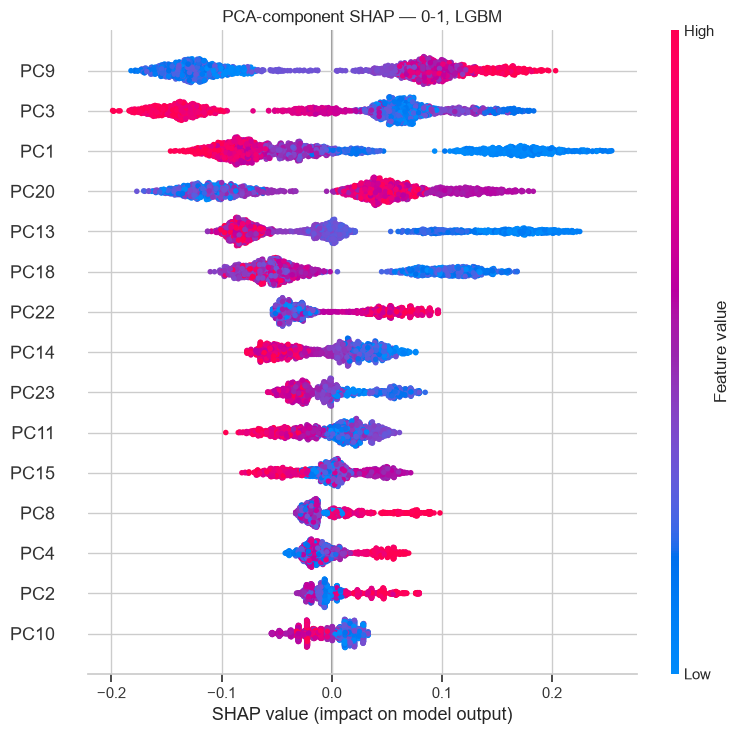

0-1 / LGBM / PC9: largest absolute original encoded-variable loadings


,loading
division_2,0.683546
division_3,-0.473361
toilet_cat_1,-0.224721
fuel_cat_2,0.207450
fuel_cat_1,-0.179011
division_4,-0.152379
bottle_1.0,0.143868
fg_dairy_1.0,0.134175


0-1 / LGBM / PC3: largest absolute original encoded-variable loadings


,loading
anc_cat_2.0,0.631939
anc_cat_1.0,-0.627393
fuel_cat_2,-0.249888
toilet_cat_1,-0.227252
bottle_1.0,0.121248
fuel_cat_1,0.114016
fg_dairy_1.0,0.109605
ub2_1.0,-0.099866


0-1 / LGBM / PC1: largest absolute original encoded-variable loadings


,loading
fvs,0.779189
fg_grain_1.0,0.298223
fg_flesh_1.0,0.257118
ub2_1.0,0.250119
bd9_3.0,-0.236701
fg_egg_1.0,0.222421
dds_4.0,0.109376
fg_dairy_1.0,0.102656


0-1 / LGBM / PC20: largest absolute original encoded-variable loadings


,loading
bf_status_2.0,0.388946
bd9_4.0,-0.388733
fg_flesh_1.0,-0.354143
bf_status_1.0,-0.333601
bd9_7.0,0.258096
dds_5.0,-0.248175
fg_dairy_1.0,0.243433
dds_4.0,0.217840


0-1 / LGBM / PC13: largest absolute original encoded-variable loadings


,loading
cm11_3.0,0.757091
cm11_1.0,-0.402852
wb4,-0.239588
fg_egg_1.0,-0.229813
cm11_4.0,-0.174363
fg_flesh_1.0,0.148030
division_4,0.124290
cm11_2.0,-0.107502


In [21]:
import shap
shap_results_pca = {}
for cohort in ["all", "0-1"]:
    if cohort not in pca_model_results:
        continue
    for item in pca_model_results[cohort]["shap_models"]:
        model, Ztest = item["model"], item["Z_test"]
        names = item["component_names"]
        Zdf = pd.DataFrame(Ztest, columns=names)
        try:
            if item["family"] in ("RF", "XGB", "LGBM", "CB"):
                explainer = shap.TreeExplainer(model)
                sv = explainer.shap_values(Zdf)
                if isinstance(sv, list):
                    sv = sv[1]
                elif np.ndim(sv) == 3:
                    sv = sv[:, :, 1]
            else:
                bg = Zdf.sample(min(50, len(Zdf)), random_state=42)
                explainer = shap.KernelExplainer(model.predict_proba, bg)
                sv_all = explainer.shap_values(Zdf.sample(min(100, len(Zdf)), random_state=42), nsamples=100)
                sv = sv_all[1] if isinstance(sv_all, list) else (sv_all[:, :, 1] if np.ndim(sv_all) == 3 else sv_all)
            importance = pd.DataFrame({"component": names, "mean_abs_shap": np.abs(sv).mean(axis=0)})
            importance = importance.sort_values("mean_abs_shap", ascending=False)
            shap_results_pca[(cohort, item["family"])] = importance
            display(importance.head(15))
            plt.figure(figsize=(8, 5))
            shap.summary_plot(sv, Zdf.iloc[:len(sv)], feature_names=names, max_display=15, show=False)
            plt.title(f"PCA-component SHAP — {cohort}, {item['family']}")
            plt.tight_layout()
            plt.show()
            # Translate top components into a descriptive loading map, not causal attribution.
            loadings = item["pca"].components_.T
            encoded_names = item["preprocessor"].get_feature_names_out()
            loadings_df = pd.DataFrame(loadings, index=encoded_names, columns=names)
            for pc in importance.head(5)["component"]:
                top_loading = loadings_df[pc].abs().sort_values(ascending=False).head(8)
                print(f"{cohort} / {item['family']} / {pc}: largest absolute original encoded-variable loadings")
                display(pd.DataFrame({"loading": loadings_df.loc[top_loading.index, pc]}).sort_values("loading", key=np.abs, ascending=False))
        except Exception as e:
            print(f"SHAP failed for {cohort}/{item['family']}: {type(e).__name__}: {e}")
